In [17]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [18]:
# DAta load 

In [19]:
df=pd.read_excel("case_study1.xlsx")
df.head()

,PROSPECTID,Total_TL,Tot_Closed_TL,Tot_Active_TL,Total_TL_opened_L6M,Tot_TL_closed_L6M,pct_tl_open_L6M,pct_tl_closed_L6M,pct_active_tl,pct_closed_tl,...,CC_TL,Consumer_TL,Gold_TL,Home_TL,PL_TL,Secured_TL,Unsecured_TL,Other_TL,Age_Oldest_TL,Age_Newest_TL
0,1,5,4,1,0,0,0.000,0.0,0.200,0.800,...,0,0,1,0,4,1,4,0,72,18
1,2,1,0,1,0,0,0.000,0.0,1.000,0.000,...,0,1,0,0,0,0,1,0,7,7
2,3,8,0,8,1,0,0.125,0.0,1.000,0.000,...,0,6,1,0,0,2,6,0,47,2
3,4,1,0,1,1,0,1.000,0.0,1.000,0.000,...,0,0,0,0,0,0,1,1,5,5
4,5,3,2,1,0,0,0.000,0.0,0.333,0.667,...,0,0,0,0,0,3,0,2,131,32


In [20]:
df1=pd.read_excel("case_study2.xlsx")
df1.head()

,PROSPECTID,time_since_recent_payment,time_since_first_deliquency,time_since_recent_deliquency,num_times_delinquent,max_delinquency_level,max_recent_level_of_deliq,num_deliq_6mts,num_deliq_12mts,num_deliq_6_12mts,...,pct_CC_enq_L6m_of_L12m,pct_PL_enq_L6m_of_ever,pct_CC_enq_L6m_of_ever,max_unsec_exposure_inPct,HL_Flag,GL_Flag,last_prod_enq2,first_prod_enq2,Credit_Score,Approved_Flag
0,1,549,35,15,11,29,29,0,0,0,...,0.0,0.0,0.0,13.333,1,0,PL,PL,696,P2
1,2,47,-99999,-99999,0,-99999,0,0,0,0,...,0.0,0.0,0.0,0.860,0,0,ConsumerLoan,ConsumerLoan,685,P2
2,3,302,11,3,9,25,25,1,9,8,...,0.0,0.0,0.0,5741.667,1,0,ConsumerLoan,others,693,P2
3,4,-99999,-99999,-99999,0,-99999,0,0,0,0,...,0.0,0.0,0.0,9.900,0,0,others,others,673,P2
4,5,583,-99999,-99999,0,-99999,0,0,0,0,...,0.0,0.0,0.0,-99999.000,0,0,AL,AL,753,P1


In [21]:
# data cleaning

In [22]:
k=[]
for i in df1.columns:
    if (df1[i]==-99999).sum() >10000:
        
        print((df1[i]==-99999).sum())
        k.append(i)
        

35949
35949
35949
12890
10832
47636
44435
23178


In [23]:
df1.drop(k,axis=1,inplace =True)

In [24]:
idx=df1[df1["time_since_recent_payment"]==-99999].index


In [25]:
for i in df1.columns:
    idx=df1[df1[i]==-99999].index
    df1.drop(idx,inplace = True)
    

In [26]:

for i in df.columns:
    if (df[i]==-99999).sum() >0:
        
        idx=df[df[i]==-99999].index
        df.drop(idx,inplace=True)


In [27]:
df.shape

(51296, 26)

In [28]:
df1.shape

(42066, 54)

In [29]:
dff=pd.merge(df,df1,how = "inner",left_on="PROSPECTID",right_on="PROSPECTID" )
dff.head()

,PROSPECTID,Total_TL,Tot_Closed_TL,Tot_Active_TL,Total_TL_opened_L6M,Tot_TL_closed_L6M,pct_tl_open_L6M,pct_tl_closed_L6M,pct_active_tl,pct_closed_tl,...,pct_PL_enq_L6m_of_L12m,pct_CC_enq_L6m_of_L12m,pct_PL_enq_L6m_of_ever,pct_CC_enq_L6m_of_ever,HL_Flag,GL_Flag,last_prod_enq2,first_prod_enq2,Credit_Score,Approved_Flag
0,1,5,4,1,0,0,0.000,0.0,0.200,0.800,...,0.0,0.0,0.000,0.0,1,0,PL,PL,696,P2
1,2,1,0,1,0,0,0.000,0.0,1.000,0.000,...,0.0,0.0,0.000,0.0,0,0,ConsumerLoan,ConsumerLoan,685,P2
2,3,8,0,8,1,0,0.125,0.0,1.000,0.000,...,0.0,0.0,0.000,0.0,1,0,ConsumerLoan,others,693,P2
3,5,3,2,1,0,0,0.000,0.0,0.333,0.667,...,0.0,0.0,0.000,0.0,0,0,AL,AL,753,P1
4,6,6,5,1,0,0,0.000,0.0,0.167,0.833,...,1.0,0.0,0.429,0.0,1,0,ConsumerLoan,PL,668,P3


In [30]:
# feauter selection 

In [31]:
# for categorical columns 

In [32]:
cat=[]
for i in dff.columns:
    if dff[i].dtype == object:
        cat.append(i)
cat

['MARITALSTATUS',
 'EDUCATION',
 'GENDER',
 'last_prod_enq2',
 'first_prod_enq2',
 'Approved_Flag']

In [33]:
# using chi square 
import scipy.stats as ss
chi=ss.chi2_contingency

In [34]:
for i in cat:
    o=(pd.crosstab(dff[i],dff['Approved_Flag']))
    statistic,pvalue,dof,expected_freq=chi(o,dff["Approved_Flag"])
    print(i,"------",statistic,"-------",pvalue,"---Approved_Flag")

MARITALSTATUS ------ 1076.9871387543772 ------- 3.578180861038862e-233 ---Approved_Flag
EDUCATION ------ 187.81675366240617 ------- 2.6942265249737532e-30 ---Approved_Flag
GENDER ------ 24.56031272141628 ------- 1.907936100186563e-05 ---Approved_Flag
last_prod_enq2 ------ 2444.9571510235596 ------- 0.0 ---Approved_Flag
first_prod_enq2 ------ 1387.5609151031795 ------- 7.84997610555419e-287 ---Approved_Flag
Approved_Flag ------ 126192.0 ------- 0.0 ---Approved_Flag


In [35]:
# numaric feature selection 
# using vif wich give multicollinearity.
from statsmodels.stats.outliers_influence import variance_inflation_factor

In [36]:
num=[]
for i in dff.columns:
    if dff[i].dtype != object:
        num.append(i)
nc=num[1:]


In [37]:
vif_data=dff[nc]
total_columns=vif_data.shape[1]

column_kept=[]
column_indx=0

for i in range(0,total_columns):
    vif_value = variance_inflation_factor(vif_data,column_indx)
    print(column_indx ,  vif_value)

    if vif_value <= 6:
        column_kept.append(nc[i])
        column_indx+=1
    else:
        vif_data= vif_data.drop(nc[i],axis=1)

C:\Users\megha\anaconda3\Lib\site-packages\statsmodels\stats\outliers_influence.py:197: RuntimeWarning: divide by zero encountered in scalar divide
  vif = 1. / (1. - r_squared_i)


0 inf


C:\Users\megha\anaconda3\Lib\site-packages\statsmodels\stats\outliers_influence.py:197: RuntimeWarning: divide by zero encountered in scalar divide
  vif = 1. / (1. - r_squared_i)


0 inf
0 11.320180023967996
0 8.363698035000336
0 6.520647877790928
0 5.149501618212625
1 2.6111110405797358


C:\Users\megha\anaconda3\Lib\site-packages\statsmodels\stats\outliers_influence.py:197: RuntimeWarning: divide by zero encountered in scalar divide
  vif = 1. / (1. - r_squared_i)


2 inf
2 1788.7926256209232
2 8.601028256477228
2 3.8328007921530785
3 6.0996533816467355
3 5.5813520096427585
4 1.9855843530987785


C:\Users\megha\anaconda3\Lib\site-packages\statsmodels\stats\outliers_influence.py:197: RuntimeWarning: divide by zero encountered in scalar divide
  vif = 1. / (1. - r_squared_i)


5 inf
5 4.809538302819343
6 23.270628983464636
6 30.595522588100053
6 4.384346405965583
7 3.0646584155234238
8 2.898639771299253
9 4.377876915347322
10 2.2078535836958433
11 4.916914200506864
12 5.214702030064725
13 3.3861625024231476
14 7.840583309478997
14 5.255034641721438


C:\Users\megha\anaconda3\Lib\site-packages\statsmodels\stats\outliers_influence.py:197: RuntimeWarning: divide by zero encountered in scalar divide
  vif = 1. / (1. - r_squared_i)


15 inf
15 7.380634506427232
15 1.421005001517573
16 8.083255010190323
16 1.6241227524040114
17 7.257811920140003
17 15.59624383268298
17 1.825857047132431
18 1.5080839450032664
19 2.172088834824577
20 2.623397553527229
21 2.2959970812106167
22 7.360578319196446
22 2.1602387773102554
23 2.8686288267891467
24 6.458218003637272
24 2.8474118865638256
25 4.7531981562840855
26 16.22735475594825
26 6.424377256363877
26 8.887080381808687
26 2.3804746142952653
27 8.609513476514548
27 13.06755093547673
27 3.500040056654654
28 1.9087955874813773
29 17.006562234161628
29 10.730485153719197
29 2.3538497522950275
30 22.104855915136433
30 2.7971639638512915
31 3.424171203217696
32 10.175021454450935
32 6.408710354561301
32 1.0011511962625617
33 3.069197305397274
34 2.8091261600643715
35 20.249538381980678
35 15.864576541593774
35 1.8331649740532168
36 1.5680839909542046
37 1.9307572353811677
38 4.331265056645244
39 9.390334396150173


In [38]:
dff[column_kept]

,pct_tl_open_L6M,pct_tl_closed_L6M,Tot_TL_closed_L12M,pct_tl_closed_L12M,Tot_Missed_Pmnt,CC_TL,Home_TL,PL_TL,Secured_TL,Unsecured_TL,...,enq_L3m,NETMONTHLYINCOME,Time_With_Curr_Empr,pct_currentBal_all_TL,CC_Flag,PL_Flag,pct_PL_enq_L6m_of_ever,pct_CC_enq_L6m_of_ever,HL_Flag,GL_Flag
0,0.000,0.00,0,0.000,0,0,0,4,1,4,...,0,51000,114,0.798,0,1,0.000,0.0,1,0
1,0.000,0.00,0,0.000,0,0,0,0,0,1,...,0,19000,50,0.370,0,0,0.000,0.0,0,0
2,0.125,0.00,0,0.000,1,0,0,0,2,6,...,0,18,191,0.585,0,0,0.000,0.0,1,0
3,0.000,0.00,0,0.000,0,0,0,0,3,0,...,0,15000,75,0.000,0,0,0.000,0.0,0,0
4,0.000,0.00,1,0.167,0,0,0,0,6,0,...,4,0,154,0.000,0,0,0.429,0.0,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
42059,0.333,0.00,0,0.000,0,0,0,0,0,3,...,1,18500,249,0.230,0,0,0.000,0.0,0,0
42060,0.000,0.25,1,0.250,0,0,0,0,2,2,...,0,25000,186,0.660,0,0,0.000,0.0,0,0
42061,0.500,0.50,1,0.500,0,0,0,0,0,2,...,2,18000,66,0.428,0,0,1.000,0.0,0,0
42062,0.000,0.00,1,0.500,0,0,0,0,0,2,...,0,12802,54,0.143,0,0,0.000,0.0,0,0


In [39]:
import scipy.stats as ss
nck=[]
for i in column_kept:
    
    g1=dff[dff["Approved_Flag"] == "P1"][i]
    g2=dff[dff["Approved_Flag"] == "P2"][i]
    g3=dff[dff["Approved_Flag"] == "P3"][i]
    g4=dff[dff["Approved_Flag"] == "P4"][i]

    f_statistic , p_value=ss.f_oneway(g1,g2,g3,g4)

    if p_value <=.05:
        nck.append(i)
    

In [40]:
dfn=dff[nck]

In [41]:
dfn

,pct_tl_open_L6M,pct_tl_closed_L6M,Tot_TL_closed_L12M,pct_tl_closed_L12M,Tot_Missed_Pmnt,CC_TL,Home_TL,PL_TL,Secured_TL,Unsecured_TL,...,time_since_recent_enq,enq_L3m,NETMONTHLYINCOME,Time_With_Curr_Empr,CC_Flag,PL_Flag,pct_PL_enq_L6m_of_ever,pct_CC_enq_L6m_of_ever,HL_Flag,GL_Flag
0,0.000,0.00,0,0.000,0,0,0,4,1,4,...,566,0,51000,114,0,1,0.000,0.0,1,0
1,0.000,0.00,0,0.000,0,0,0,0,0,1,...,209,0,19000,50,0,0,0.000,0.0,0,0
2,0.125,0.00,0,0.000,1,0,0,0,2,6,...,587,0,18,191,0,0,0.000,0.0,1,0
3,0.000,0.00,0,0.000,0,0,0,0,3,0,...,3951,0,15000,75,0,0,0.000,0.0,0,0
4,0.000,0.00,1,0.167,0,0,0,0,6,0,...,7,4,0,154,0,0,0.429,0.0,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
42059,0.333,0.00,0,0.000,0,0,0,0,0,3,...,0,1,18500,249,0,0,0.000,0.0,0,0
42060,0.000,0.25,1,0.250,0,0,0,0,2,2,...,203,0,25000,186,0,0,0.000,0.0,0,0
42061,0.500,0.50,1,0.500,0,0,0,0,0,2,...,1,2,18000,66,0,0,1.000,0.0,0,0
42062,0.000,0.00,1,0.500,0,0,0,0,0,2,...,242,0,12802,54,0,0,0.000,0.0,0,0


In [27]:
# catogorical selection 

In [42]:
dff[cat].head()

,MARITALSTATUS,EDUCATION,GENDER,last_prod_enq2,first_prod_enq2,Approved_Flag
0,Married,12TH,M,PL,PL,P2
1,Single,GRADUATE,F,ConsumerLoan,ConsumerLoan,P2
2,Married,SSC,M,ConsumerLoan,others,P2
3,Married,POST-GRADUATE,M,AL,AL,P1
4,Married,12TH,M,ConsumerLoan,PL,P3


In [43]:
# working in EDUCATUON  columns

In [44]:
# 'SSC' - 1
# '12TH' - 2 
# 'GRADUATE' - 3 
# 'UNDER GRADUATE' - 3
# 'POST-GRADUATE' - 4 
# 'OTHERS' - 1
# 'PROFESSIONAL' - 3

In [45]:
idx=dff[(dff["EDUCATION"]=="SSC") | (dff["EDUCATION"]=="OTHERS")].index
idx
dff.loc[idx,"EDUCATION"]=1

In [46]:
idx=dff[(dff["EDUCATION"]=="UNDER GRADUATE") | (dff["EDUCATION"]=="GRADUATE") | (dff["EDUCATION"]=="PROFESSIONAL")].index
idx
dff.loc[idx,"EDUCATION"]=3

In [47]:
idx=dff[(dff["EDUCATION"]=="12TH")].index
idx
dff.loc[idx,"EDUCATION"]=2

In [48]:
idx=dff[(dff["EDUCATION"]=="POST-GRADUATE") ].index
idx
dff.loc[idx,"EDUCATION"]=4

In [49]:
dff["EDUCATION"].value_counts()

EDUCATION
3    18931
2    11703
1     9532
4     1898
Name: count, dtype: int64

In [123]:
# GENDER COLUMN

In [50]:
from sklearn.preprocessing import OneHotEncoder
ohe=OneHotEncoder()


In [51]:
dff["GENDER"].value_counts()

GENDER
M    37345
F     4719
Name: count, dtype: int64

In [52]:
# 1 = male 
# 0 = female

In [53]:
dff["GENDER"]=pd.get_dummies(dff["GENDER"],dtype=int)["M"]

In [54]:
# Married = 1
# single = 0 

In [55]:
dff["MARITALSTATUS"].unique()

array(['Married', 'Single'], dtype=object)

In [56]:
dff["MARITALSTATUS"]=pd.DataFrame(ohe.fit_transform(dff[["MARITALSTATUS"]]).toarray(),dtype=int)[0]
dff[cat].head()

,MARITALSTATUS,EDUCATION,GENDER,last_prod_enq2,first_prod_enq2,Approved_Flag
0,1,2,1,PL,PL,P2
1,0,3,0,ConsumerLoan,ConsumerLoan,P2
2,1,1,1,ConsumerLoan,others,P2
3,1,4,1,AL,AL,P1
4,1,2,1,ConsumerLoan,PL,P3


In [57]:
dff["last_prod_enq2"].value_counts()

last_prod_enq2
ConsumerLoan    16480
others          13653
PL               7553
CC               2195
AL               1353
HL                830
Name: count, dtype: int64

In [58]:
dff["first_prod_enq2"].value_counts()

first_prod_enq2
others          20640
ConsumerLoan    11075
PL               4431
AL               2641
CC               1988
HL               1289
Name: count, dtype: int64

In [59]:
df=pd.concat([dff["PROSPECTID"],dff[nck],dff[cat]],axis=1)
df.head()

,PROSPECTID,pct_tl_open_L6M,pct_tl_closed_L6M,Tot_TL_closed_L12M,pct_tl_closed_L12M,Tot_Missed_Pmnt,CC_TL,Home_TL,PL_TL,Secured_TL,...,pct_PL_enq_L6m_of_ever,pct_CC_enq_L6m_of_ever,HL_Flag,GL_Flag,MARITALSTATUS,EDUCATION,GENDER,last_prod_enq2,first_prod_enq2,Approved_Flag
0,1,0.000,0.0,0,0.000,0,0,0,4,1,...,0.000,0.0,1,0,1,2,1,PL,PL,P2
1,2,0.000,0.0,0,0.000,0,0,0,0,0,...,0.000,0.0,0,0,0,3,0,ConsumerLoan,ConsumerLoan,P2
2,3,0.125,0.0,0,0.000,1,0,0,0,2,...,0.000,0.0,1,0,1,1,1,ConsumerLoan,others,P2
3,5,0.000,0.0,0,0.000,0,0,0,0,3,...,0.000,0.0,0,0,1,4,1,AL,AL,P1
4,6,0.000,0.0,1,0.167,0,0,0,0,6,...,0.429,0.0,1,0,1,2,1,ConsumerLoan,PL,P3


In [60]:
df["Approved_Flag"].unique()

array(['P2', 'P1', 'P3', 'P4'], dtype=object)

In [64]:
df.to_csv("data.csv",index=False)

In [65]:
df=pd.read_csv("data.csv")
df.head()

,PROSPECTID,pct_tl_open_L6M,pct_tl_closed_L6M,Tot_TL_closed_L12M,pct_tl_closed_L12M,Tot_Missed_Pmnt,CC_TL,Home_TL,PL_TL,Secured_TL,...,pct_PL_enq_L6m_of_ever,pct_CC_enq_L6m_of_ever,HL_Flag,GL_Flag,MARITALSTATUS,EDUCATION,GENDER,last_prod_enq2,first_prod_enq2,Approved_Flag
0,1,0.000,0.0,0,0.000,0,0,0,4,1,...,0.000,0.0,1,0,1,2,1,PL,PL,2
1,2,0.000,0.0,0,0.000,0,0,0,0,0,...,0.000,0.0,0,0,0,3,0,ConsumerLoan,ConsumerLoan,2
2,3,0.125,0.0,0,0.000,1,0,0,0,2,...,0.000,0.0,1,0,1,1,1,ConsumerLoan,others,2
3,5,0.000,0.0,0,0.000,0,0,0,0,3,...,0.000,0.0,0,0,1,4,1,AL,AL,1
4,6,0.000,0.0,1,0.167,0,0,0,0,6,...,0.429,0.0,1,0,1,2,1,ConsumerLoan,PL,3


In [66]:
# feature enggennering on approved_flag
df["Approved_Flag"].unique()

array([2, 1, 3, 4])

In [67]:
idx=df[df["Approved_Flag"]=="P1"].index
df.loc[idx,"Approved_Flag"]=1

idx=df[df["Approved_Flag"]=="P2"].index
df.loc[idx,"Approved_Flag"]=2

idx=df[df["Approved_Flag"]=="P3"].index
df.loc[idx,"Approved_Flag"]=3

idx=df[df["Approved_Flag"]=="P4"].index
df.loc[idx,"Approved_Flag"]=4

# EDA 

In [138]:
df.columns

Index(['PROSPECTID', 'pct_tl_open_L6M', 'pct_tl_closed_L6M',
       'Tot_TL_closed_L12M', 'pct_tl_closed_L12M', 'Tot_Missed_Pmnt', 'CC_TL',
       'Home_TL', 'PL_TL', 'Secured_TL', 'Unsecured_TL', 'Other_TL',
       'Age_Oldest_TL', 'Age_Newest_TL', 'time_since_recent_payment',
       'max_recent_level_of_deliq', 'num_deliq_6_12mts', 'num_times_60p_dpd',
       'num_std_12mts', 'num_sub', 'num_sub_6mts', 'num_sub_12mts', 'num_dbt',
       'num_dbt_12mts', 'num_lss', 'recent_level_of_deliq', 'CC_enq_L12m',
       'PL_enq_L12m', 'time_since_recent_enq', 'enq_L3m', 'NETMONTHLYINCOME',
       'Time_With_Curr_Empr', 'CC_Flag', 'PL_Flag', 'pct_PL_enq_L6m_of_ever',
       'pct_CC_enq_L6m_of_ever', 'HL_Flag', 'GL_Flag', 'MARITALSTATUS',
       'EDUCATION', 'GENDER', 'last_prod_enq2', 'first_prod_enq2',
       'Approved_Flag'],
      dtype='object')

In [68]:
# univarient analyisis

In [314]:
# 'NETMONTHLYINCOME'

df["NETMONTHLYINCOME"].describe()

count    4.206400e+04
mean     2.692990e+04
std      2.084300e+04
min      0.000000e+00
25%      1.800000e+04
50%      2.400000e+04
75%      3.100000e+04
max      2.500000e+06
Name: NETMONTHLYINCOME, dtype: float64

<Axes: ylabel='NETMONTHLYINCOME'>

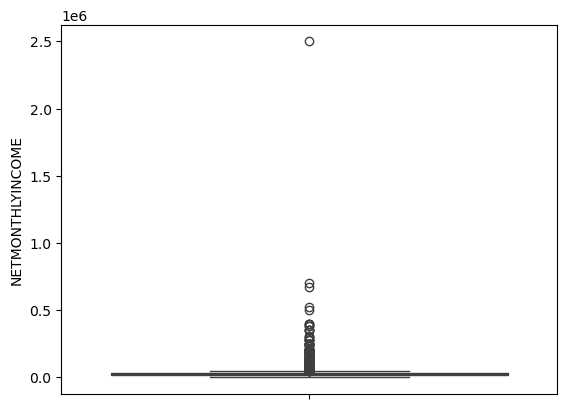

In [315]:
sns.boxplot(df["NETMONTHLYINCOME"])

<Axes: ylabel='Density'>

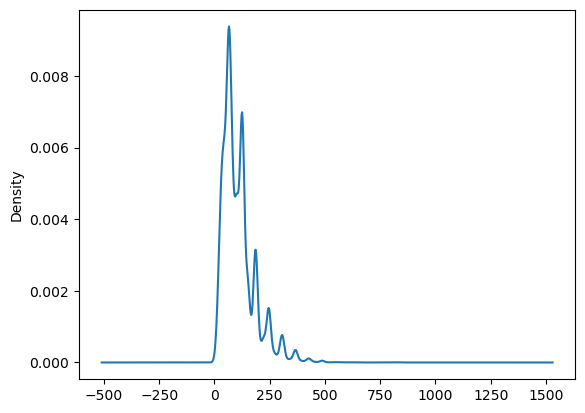

In [209]:
df["Time_With_Curr_Empr"].plot(kind="kde")

In [210]:
df["Time_With_Curr_Empr"].describe()

count    42064.000000
mean       110.345783
std         75.629967
min          0.000000
25%         61.000000
50%         92.000000
75%        131.000000
max       1020.000000
Name: Time_With_Curr_Empr, dtype: float64

<Axes: ylabel='Time_With_Curr_Empr'>

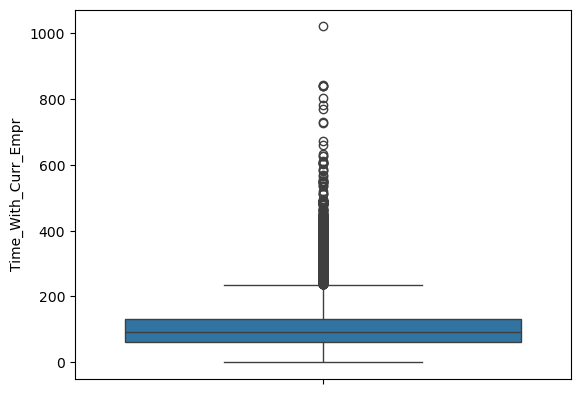

In [212]:
sns.boxplot(df["Time_With_Curr_Empr"])

In [214]:
df["Tot_Missed_Pmnt"].describe()

count    42064.000000
mean         0.525746
std          1.106442
min          0.000000
25%          0.000000
50%          0.000000
75%          1.000000
max         34.000000
Name: Tot_Missed_Pmnt, dtype: float64

<Axes: ylabel='Tot_Missed_Pmnt'>

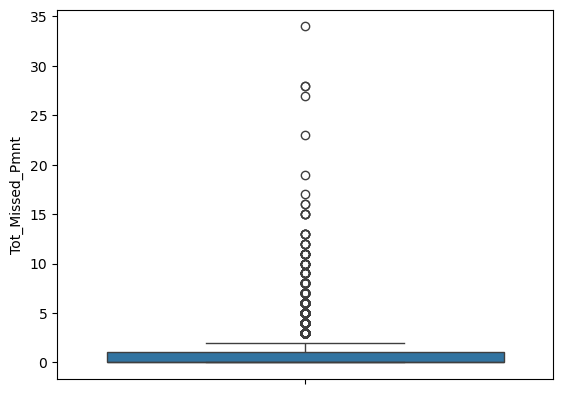

In [216]:
sns.boxplot(df["Tot_Missed_Pmnt"])

In [268]:
# highly approvd 2 

<Axes: ylabel='proportion'>

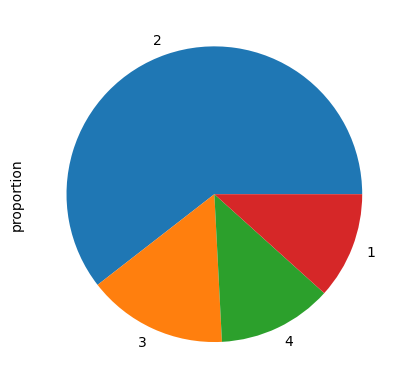

In [267]:
(df["Approved_Flag"].value_counts(normalize=True)*100).plot(kind="pie")


In [219]:
df.columns

Index(['PROSPECTID', 'pct_tl_open_L6M', 'pct_tl_closed_L6M',
       'Tot_TL_closed_L12M', 'pct_tl_closed_L12M', 'Tot_Missed_Pmnt', 'CC_TL',
       'Home_TL', 'PL_TL', 'Secured_TL', 'Unsecured_TL', 'Other_TL',
       'Age_Oldest_TL', 'Age_Newest_TL', 'time_since_recent_payment',
       'max_recent_level_of_deliq', 'num_deliq_6_12mts', 'num_times_60p_dpd',
       'num_std_12mts', 'num_sub', 'num_sub_6mts', 'num_sub_12mts', 'num_dbt',
       'num_dbt_12mts', 'num_lss', 'recent_level_of_deliq', 'CC_enq_L12m',
       'PL_enq_L12m', 'time_since_recent_enq', 'enq_L3m', 'NETMONTHLYINCOME',
       'Time_With_Curr_Empr', 'CC_Flag', 'PL_Flag', 'pct_PL_enq_L6m_of_ever',
       'pct_CC_enq_L6m_of_ever', 'HL_Flag', 'GL_Flag', 'MARITALSTATUS',
       'EDUCATION', 'GENDER', 'last_prod_enq2', 'first_prod_enq2',
       'Approved_Flag'],
      dtype='object')

# bivartae anlysis

In [69]:
# Gender with Approved Flag


# main priority is male for all approval flag
# male is higher in percentage

In [68]:
pd.crosstab(df['GENDER'],df['Approved_Flag'],normalize="index")*100

Approved_Flag,1,2,3,4
GENDER,,,,
0,9.557110,62.428481,15.766052,12.248358
1,11.934663,60.265096,15.252376,12.547865


In [93]:
Gender=(df.groupby("GENDER")["Approved_Flag"].value_counts(normalize=True)*100).reset_index()


In [76]:

m=Gender[Gender["GENDER"]==1][["Approved_Flag","proportion"]].sort_values("Approved_Flag")
f=Gender[Gender["GENDER"]==0][["Approved_Flag","proportion"]].sort_values("Approved_Flag")
m

,Approved_Flag,proportion
7,1,11.934663
4,2,60.265096
5,3,15.252376
6,4,12.547865


In [77]:
x=np.sort(df["Approved_Flag"].unique())
x

array([1, 2, 3, 4])

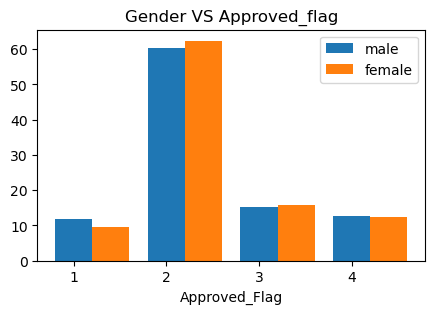

In [92]:
plt.figure(figsize=(5,3))
plt.bar(x,m["proportion"],width=0.4)
plt.bar(x+0.4,f["proportion"],width=0.4)
plt.legend(["male","female"])
plt.xticks([1,2,3,4])
plt.xlabel("Approved_Flag")
plt.title("Gender VS Approved_flag")


plt.show()

In [80]:
# education with approval flag

# according to Eduction :- grauate / under graduate / professional are higher rate %  priority in all approval category 

In [94]:
pd.crosstab(df["EDUCATION"],df["Approved_Flag"],normalize='index')*100

Approved_Flag,1,2,3,4
EDUCATION,,,,
1,11.235837,62.096097,15.012589,11.655476
2,10.176878,62.599334,16.072802,11.150987
3,12.371243,58.597010,15.197295,13.834451
4,16.016860,58.693361,13.224447,12.065332


In [101]:
Edu=(df.groupby("EDUCATION")["Approved_Flag"].value_counts(normalize=True)*100).reset_index()

e1=Edu[Edu["EDUCATION"]==1][["Approved_Flag","proportion"]].sort_values("Approved_Flag")
e2=Edu[Edu["EDUCATION"]==2][["Approved_Flag","proportion"]].sort_values("Approved_Flag")
e3=Edu[Edu["EDUCATION"]==3][["Approved_Flag","proportion"]].sort_values("Approved_Flag")
e4=Edu[Edu["EDUCATION"]==4][["Approved_Flag","proportion"]].sort_values("Approved_Flag")

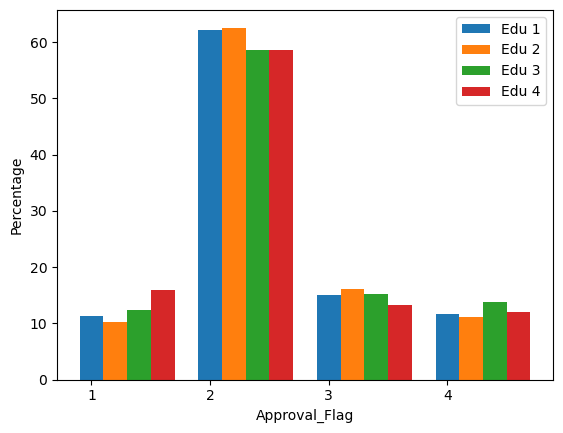

In [105]:
x=np.sort(df["Approved_Flag"].unique())
w=0.2
plt.bar(x,e1["proportion"],width=0.2)
plt.bar(x+w,e2["proportion"],width=0.2)
plt.bar(x+(2*w),e3["proportion"],width=0.2)
plt.bar(x+(3*w),e4["proportion"],width=0.2)

plt.legend(["Edu 1","Edu 2","Edu 3","Edu 4"])
plt.xticks([1,2,3,4])

plt.xlabel("Approval_Flag")
plt.ylabel("Percentage")
plt.show()

In [204]:
# Maritial status with Approved Flag

# highly prefered male 

In [206]:
(pd.crosstab(df["MARITALSTATUS"],df["Approved_Flag"],normalize="columns")*100)

Approved_Flag,1,2,3,4
MARITALSTATUS,,,,
0,9.637327,26.457646,31.878882,36.43617
1,90.362673,73.542354,68.121118,63.56383


In [111]:
Mar=(df.groupby("Approved_Flag")["MARITALSTATUS"].value_counts(normalize=True)*100).reset_index()


In [107]:
e1=Mar[Mar["MARITALSTATUS"]==1][["Approved_Flag","proportion"]]
e2=Mar[Mar["MARITALSTATUS"]==0][["Approved_Flag","proportion"]]


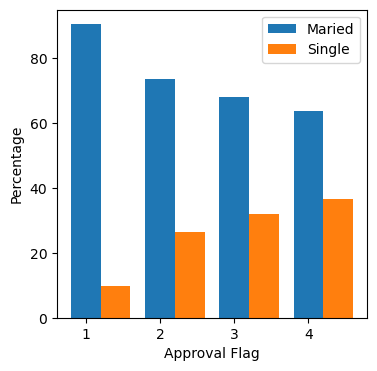

In [110]:
x=np.sort(df["Approved_Flag"].unique())
w=0.4
plt.figure(figsize=(4,4))
plt.bar(x,e1["proportion"],width=w)
plt.bar(x+w,e2["proportion"],width=w)
plt.xticks([1,2,3,4])
plt.xlabel("Approval Flag")
plt.ylabel("Percentage")
plt.legend(["Maried","Single"])

plt.show()

In [125]:
# misised payments 

# 70 % are are not missed payments
# 30 % percent are missed payment equal or grether than 1 

# thier are alse some outliers .

In [112]:
df.columns

Index(['PROSPECTID', 'pct_tl_open_L6M', 'pct_tl_closed_L6M',
       'Tot_TL_closed_L12M', 'pct_tl_closed_L12M', 'Tot_Missed_Pmnt', 'CC_TL',
       'Home_TL', 'PL_TL', 'Secured_TL', 'Unsecured_TL', 'Other_TL',
       'Age_Oldest_TL', 'Age_Newest_TL', 'time_since_recent_payment',
       'max_recent_level_of_deliq', 'num_deliq_6_12mts', 'num_times_60p_dpd',
       'num_std_12mts', 'num_sub', 'num_sub_6mts', 'num_sub_12mts', 'num_dbt',
       'num_dbt_12mts', 'num_lss', 'recent_level_of_deliq', 'CC_enq_L12m',
       'PL_enq_L12m', 'time_since_recent_enq', 'enq_L3m', 'NETMONTHLYINCOME',
       'Time_With_Curr_Empr', 'CC_Flag', 'PL_Flag', 'pct_PL_enq_L6m_of_ever',
       'pct_CC_enq_L6m_of_ever', 'HL_Flag', 'GL_Flag', 'MARITALSTATUS',
       'EDUCATION', 'GENDER', 'last_prod_enq2', 'first_prod_enq2',
       'Approved_Flag'],
      dtype='object')

<Axes: ylabel='Tot_Missed_Pmnt'>

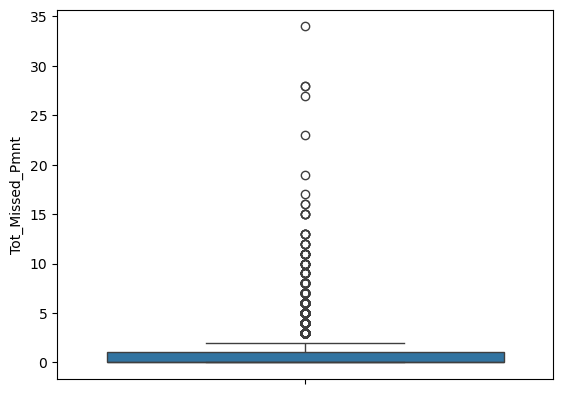

In [122]:
sns.boxplot(df["Tot_Missed_Pmnt"])

In [131]:
def Tmp(i):
    if i == 0:
        return "No"
    elif i < 4:
        return "Low"
    else:
        return "High"
    

In [136]:
df["Missed_paymnet"]=df["Tot_Missed_Pmnt"].apply(Tmp)


<Axes: xlabel='Approved_Flag'>

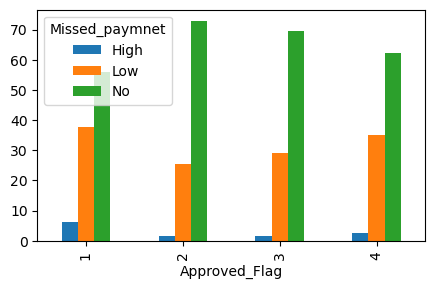

In [176]:
(pd.crosstab(df["Approved_Flag"],df["Missed_paymnet"],normalize="index")*100).plot(kind="bar",figsize=(5,3))

In [177]:
# deliq VS Approved_Flag

In [167]:
df["deliq"]=(df["num_deliq_6_12mts"].apply(Tmp))

<Axes: xlabel='Approved_Flag'>

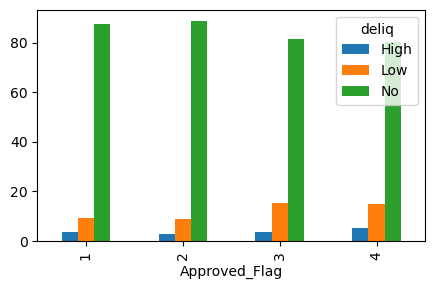

In [174]:
(pd.crosstab(df["Approved_Flag"],df["deliq"],normalize="index")*100).plot(kind="bar",figsize=(5,3))

In [185]:
# 60_dpd VS Approved_Flag

In [183]:
df["60_dpd"]=df['num_times_60p_dpd'].apply(Tmp)


<Axes: xlabel='Approved_Flag'>

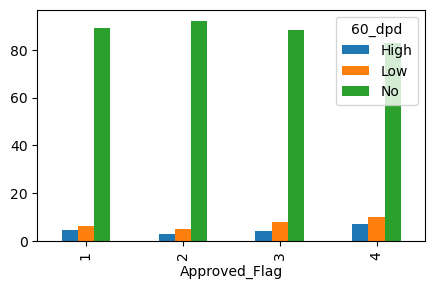

In [184]:
(pd.crosstab(df["Approved_Flag"],df["60_dpd"],normalize="index")*100).plot(kind="bar",figsize=(5,3))

In [188]:
# count of :

# loss account :-   1.6 % 
# Sub_stamdard_account :- 2.5 %
# doubtfull-account :-  6.3 %



In [201]:
ls=(df["num_lss"].sum()/len(df["num_lss"]))*100
ls

np.float64(1.6712628375808292)

In [202]:
dbt=(df["num_dbt"].sum()/len(df["num_dbt"]))*100
dbt

np.float64(2.451027006466337)

In [203]:
sub=(df["num_sub"].sum()/len(df["num_sub"]))*100
sub

np.float64(6.383130467858502)

In [206]:
y=[int(ls),int(dbt),int(sub)]
x=["loss","doubt","sub"]


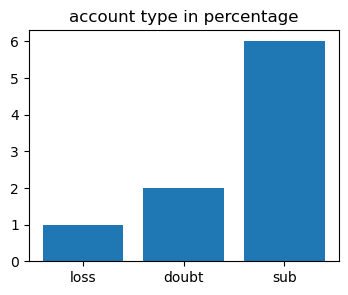

In [211]:
plt.figure(figsize=(4,3))
plt.title("account type in percentage")
plt.bar(x,y)
plt.show()

In [270]:
# credit card and personal loan Enquiry:-  

# personal loan :-
# approved 4 have high pl enqiery  comparesion to all groups
# but in all group thier are high no enquiry for pl .

# credit card :- 
# thier are no enquiry for credit card 
# few enquiry in all approved flag




In [226]:
df["cc_enq"]=df["CC_enq_L12m"].apply(Tmp)
y=(df["cc_enq"].value_counts()/len(df["cc_enq"]))*100

In [227]:
df["pl_enq"]=df["PL_enq_L12m"].apply(Tmp)
y1=(df["pl_enq"].value_counts()/len(df["pl_enq"]))*100

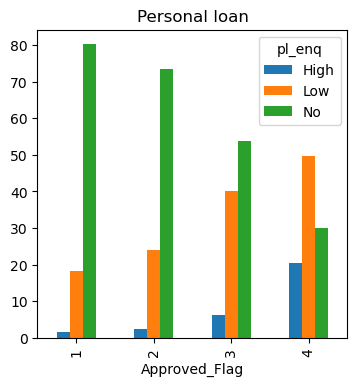

In [268]:
(pd.crosstab(df["Approved_Flag"],df["pl_enq"],normalize="index")*100).plot(kind="bar",figsize=(4,4))
plt.title("Personal loan")

plt.show()

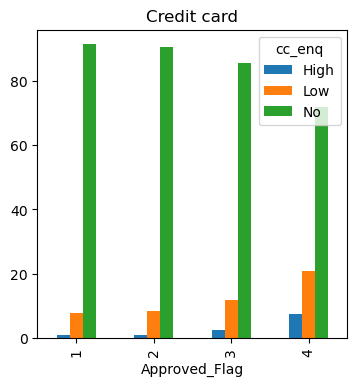

In [266]:
(pd.crosstab(df["Approved_Flag"],df["cc_enq"],normalize="index")*100).plot(kind="bar",figsize=(4,4))
plt.title("Credit card")
plt.show()

In [292]:
df["total_acc"]=df["CC_TL"]+df["Home_TL"]+df["PL_TL"]+df["Other_TL"]+df["Secured_TL"]+ df["Unsecured_TL"]


<Axes: ylabel='total_acc'>

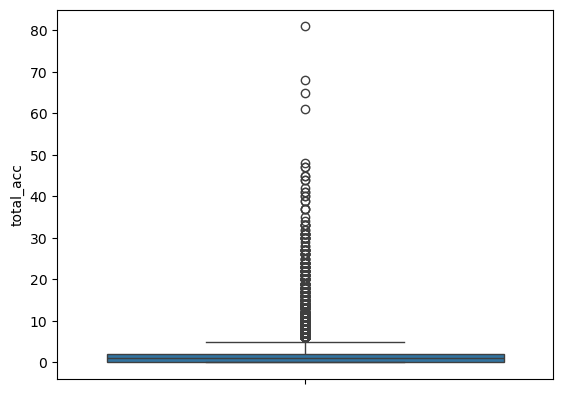

In [282]:
sns.boxplot(df["total_acc"])

In [283]:
df.columns

Index(['PROSPECTID', 'pct_tl_open_L6M', 'pct_tl_closed_L6M',
       'Tot_TL_closed_L12M', 'pct_tl_closed_L12M', 'Tot_Missed_Pmnt', 'CC_TL',
       'Home_TL', 'PL_TL', 'Secured_TL', 'Unsecured_TL', 'Other_TL',
       'Age_Oldest_TL', 'Age_Newest_TL', 'time_since_recent_payment',
       'max_recent_level_of_deliq', 'num_deliq_6_12mts', 'num_times_60p_dpd',
       'num_std_12mts', 'num_sub', 'num_sub_6mts', 'num_sub_12mts', 'num_dbt',
       'num_dbt_12mts', 'num_lss', 'recent_level_of_deliq', 'CC_enq_L12m',
       'PL_enq_L12m', 'time_since_recent_enq', 'enq_L3m', 'NETMONTHLYINCOME',
       'Time_With_Curr_Empr', 'CC_Flag', 'PL_Flag', 'pct_PL_enq_L6m_of_ever',
       'pct_CC_enq_L6m_of_ever', 'HL_Flag', 'GL_Flag', 'MARITALSTATUS',
       'EDUCATION', 'GENDER', 'last_prod_enq2', 'first_prod_enq2',
       'Approved_Flag', 'Missed_paymnet', 'deliq', '60_dpd', 'cc_enq',
       'pl_enq', 'total_acc'],
      dtype='object')

In [323]:
s=df.groupby("Approved_Flag")["PL_Flag"].value_counts().reset_index()
pl=s[s["PL_Flag"]==1]["count"].values

In [322]:
s=df.groupby("Approved_Flag")["CC_Flag"].value_counts().reset_index()
cc=s[s["CC_Flag"]==1]["count"].values

In [321]:
s=df.groupby("Approved_Flag")["HL_Flag"].value_counts().reset_index()
hl=s[s["HL_Flag"]==1]["count"].values

In [315]:
s=df.groupby("Approved_Flag")["GL_Flag"].value_counts().reset_index()
gl=s[s["GL_Flag"]==1]["count"].values

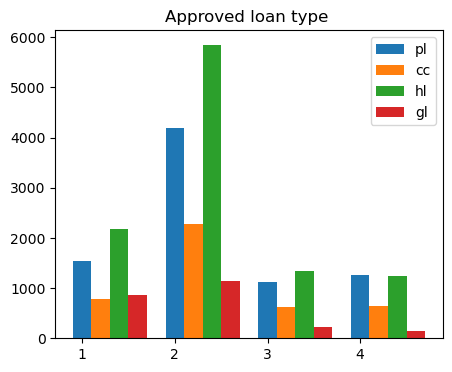

In [334]:
x=np.array([1,2,3,4])
w=0.2

plt.figure(figsize=(5,4))
plt.bar(x,pl,width=w,label="pl")
plt.bar(x+w,cc,width=w,label="cc")
plt.bar(x+(2*w),hl,width=w,label="hl")
plt.bar(x+(3*w),gl,width=w,label="gl")

plt.legend()
plt.title("Approved loan type ")
plt.xticks([1,2,3,4])
plt.show()

In [345]:
df["Age_Oldest_TL"].describe()

count    42064.000000
mean        46.498074
std         42.109230
min          0.000000
25%         14.000000
50%         34.000000
75%         65.000000
max        385.000000
Name: Age_Oldest_TL, dtype: float64

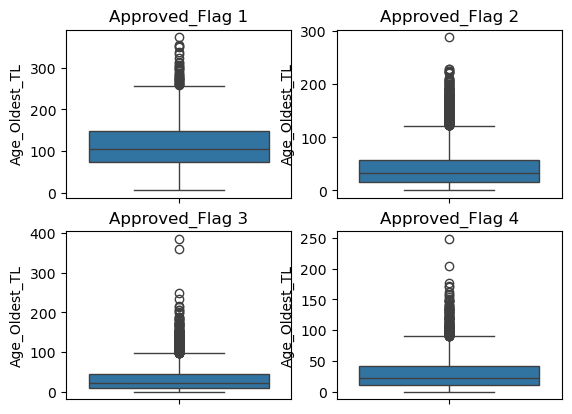

In [357]:
for i in np.sort(df["Approved_Flag"].unique()):
    plt.subplot(2,2,i)
    sns.boxplot(df[df["Approved_Flag"]==i]["Age_Oldest_TL"])
    plt.title(f"Approved_Flag {i}")

# thier are more outlier
# but in approved flag 1 are less camparision to all other 

In [370]:
# 0-50  are higher acounts 


<Axes: ylabel='Frequency'>

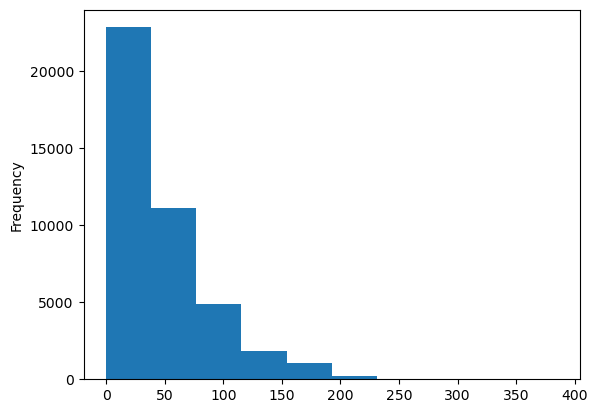

In [369]:
df["Age_Oldest_TL"].plot(kind="hist",bins=10)